<a href="https://colab.research.google.com/github/panuza1/mango-leaf-cnn/blob/main/DL_mango_leaf_disease_project_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import Libraries

In [ ]:
import os
import random
import numpy as np
import pandas as pd

from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

2. Download Dataset

ดาวน์โหลด Mango Leaf Disease Dataset จาก Kaggle

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("aryashah2k/mango-leaf-disease-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mango-leaf-disease-dataset' dataset.
Path to dataset files: /kaggle/input/mango-leaf-disease-dataset


3. Explore Dataset

ตรวจสอบโครงสร้าง Folder และจำนวนภาพในแต่ละ Class ก่อนนำไปใช้งาน

In [ ]:
data_dir = Path(path)

# Display folders
for folder in data_dir.iterdir():
    if folder.is_dir():
        images = list(folder.glob("*"))
        print(folder.name, ":", len(images), "images")

Powdery Mildew : 500 images
Cutting Weevil : 500 images
Anthracnose : 500 images
Bacterial Canker : 500 images
Sooty Mould : 500 images
Gall Midge : 500 images
Healthy : 500 images
Die Back : 500 images


4. Collect Image Paths and Labels

รวบรวมตำแหน่งไฟล์ภาพและ Label ของแต่ละภาพ โดยกำหนดให้แต่ละ Folder เป็นหนึ่ง Class

In [ ]:
# Supported image formats
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_paths = []
labels = []

class_names = sorted([
    folder.name for folder in data_dir.iterdir()
    if folder.is_dir()
])

print("Classes:", class_names)
print("Number of classes:", len(class_names))

# Collect images
for class_name in class_names:
    class_dir = data_dir / class_name

    for img_path in class_dir.rglob("*"):
        if img_path.suffix.lower() in image_extensions:
            image_paths.append(str(img_path))
            labels.append(class_name)

# Create DataFrame
df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

print("Total images:", len(df))
print(df["label"].value_counts())

Classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']
Number of classes: 8
Total images: 4000
label
Anthracnose         500
Bacterial Canker    500
Cutting Weevil      500
Die Back            500
Gall Midge          500
Healthy             500
Powdery Mildew      500
Sooty Mould         500
Name: count, dtype: int64


5. Split Dataset (train 70% : validation 15% : test 15%)

ใช้ train_test_split() จาก Scikit-learn โดยกำหนด stratify เพื่อรักษาสัดส่วนของแต่ละ Class

In [ ]:
# Set random seed
SEED = 42

# Split Train (70%) and Temporary (30%)
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

# Split Validation (15%) and Test (15%)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

# Reset index
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name} Distribution:")
    print(data["label"].value_counts())

Train: 2800
Validation: 600
Test: 600

Train Distribution:
label
Gall Midge          350
Healthy             350
Die Back            350
Anthracnose         350
Cutting Weevil      350
Sooty Mould         350
Powdery Mildew      350
Bacterial Canker    350
Name: count, dtype: int64

Validation Distribution:
label
Die Back            75
Gall Midge          75
Bacterial Canker    75
Healthy             75
Sooty Mould         75
Cutting Weevil      75
Powdery Mildew      75
Anthracnose         75
Name: count, dtype: int64

Test Distribution:
label
Die Back            75
Healthy             75
Powdery Mildew      75
Cutting Weevil      75
Anthracnose         75
Gall Midge          75
Sooty Mould         75
Bacterial Canker    75
Name: count, dtype: int64


6. Image Preprocessing and Data Augmentation

เตรียมภาพให้มีขนาดเท่ากันที่ 224 × 224 pixels เพื่อให้สามารถนำเข้า GoogLeNet ได้

นอกจากนี้จะใช้ Data Augmentation เฉพาะ Training Set เพื่อเพิ่มความหลากหลายของข้อมูล โดยไม่เปลี่ยนแปลงข้อมูลที่ใช้ประเมินประสิทธิภาพ

Training Transform
- Resize และ Crop ภาพให้มีขนาด 224 × 224
- Random Horizontal Flip
- Random Rotation
- Color Jitter
- Normalize ภาพด้วย ImageNet Mean และ Standard Deviation

Validation และ Test Transform
- Resize ภาพ
- Center Crop
- Normalize ภาพ

In [ ]:
# ImageNet normalization
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Validation and Test transformations
test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

7. Create Custom Dataset

สร้าง Custom Dataset เพื่อให้ PyTorch สามารถอ่านภาพและแปลง Label เป็นตัวเลขได้

In [ ]:
class MangoLeafDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

        self.class_to_idx = {
            name: idx
            for idx, name in enumerate(class_names)
        }

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        img_path = self.dataframe.iloc[index]["image_path"]
        label = self.dataframe.iloc[index]["label"]

        # Load image
        image = Image.open(img_path).convert("RGB")

        # Apply transformations
        if self.transform:
            image = self.transform(image)

        # Convert label to number
        label = self.class_to_idx[label]

        return image, label

8. Create Dataset and DataLoader

สร้าง Dataset แยกเป็น 3 ชุด ได้แก่ Train, Validation และ Test

In [ ]:
# Create datasets
train_dataset = MangoLeafDataset(
    train_df,
    transform=train_transform
)

val_dataset = MangoLeafDataset(
    val_df,
    transform=test_transform
)

test_dataset = MangoLeafDataset(
    test_df,
    transform=test_transform
)

# Create DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

9. Check Prepared Data

ตรวจสอบว่าข้อมูลสามารถนำเข้าโมเดลได้ถูกต้องหรือไม่

In [ ]:
# Get one batch
images, labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Image shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])
Classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']
Number of classes: 8


10. Visualize Sample Images

ลองแสดงภาพตัวอย่างหลังผ่าน Preprocessing เพื่อดูว่าภาพถูกแปลงอย่างถูกต้องหรือไม่

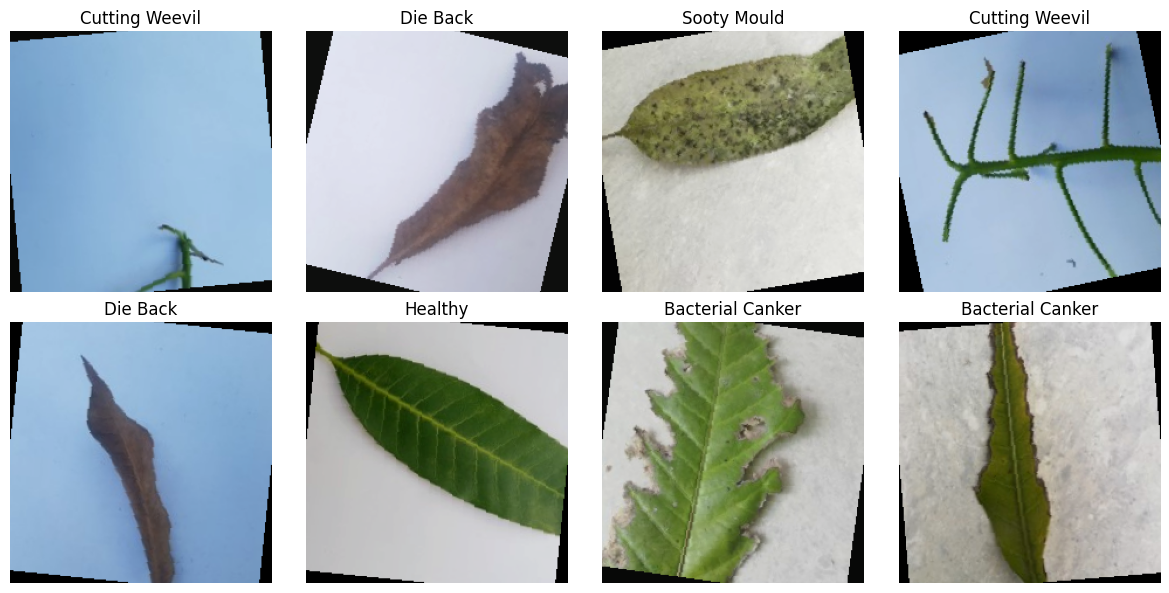

In [ ]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):

    # Reverse normalization
    img = images[i].permute(1, 2, 0).numpy()
    img = img * np.array(std) + np.array(mean)
    img = np.clip(img, 0, 1)

    ax.imshow(img)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

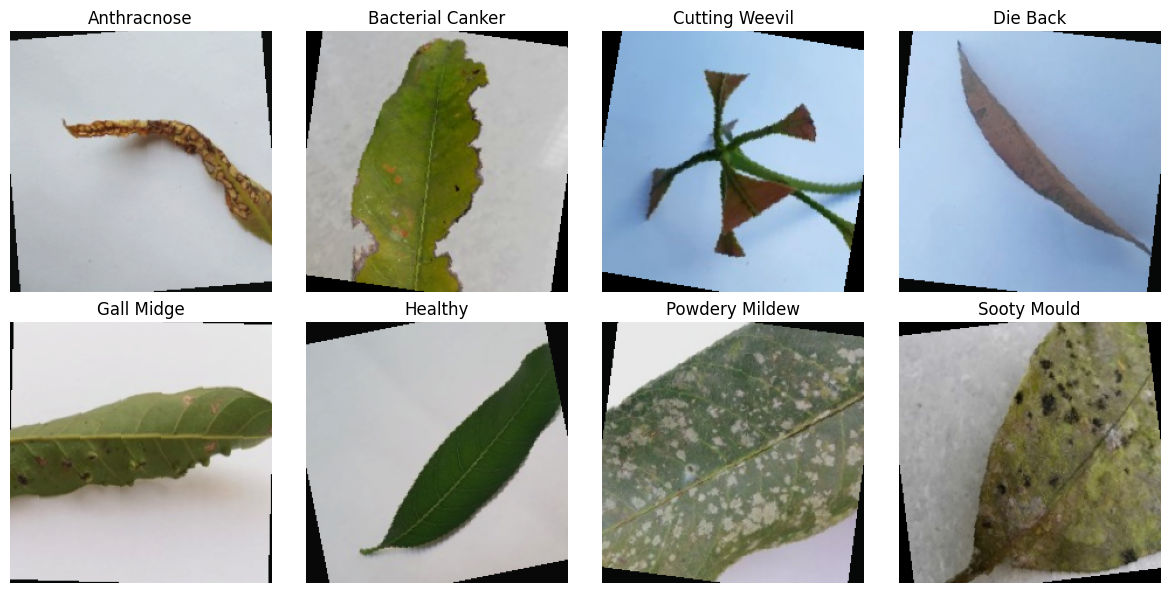

In [ ]:
import math
import matplotlib.pyplot as plt
import numpy as np

# 1. เก็บภาพตัวอย่างคลาสละ 1 ภาพ
class_images = {}
num_classes = len(class_names)

for images, labels in train_loader:
    for img, label in zip(images, labels):
        label_idx = label.item()
        if label_idx not in class_images:
            class_images[label_idx] = img

    # หยุดวนลูปทันทีเมื่อเก็บครบทุกคลาสแล้ว
    if len(class_images) == num_classes:
        break

# 2. จัดขนาดตาราง (Grid) อัตโนมัติตามจำนวนคลาส (กำหนดไว้ที่ 4 คอลัมน์)
cols = 4
rows = math.ceil(num_classes / cols)
fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
axes = axes.flatten()  # แปลงเป็น 1 มิติเพื่อให้ง่ายต่อการวนลูป

# 3. แสดงผลเรียงตามลำดับคลาส (0, 1, 2, ...)
for i in range(len(axes)):
    ax = axes[i]
    if i in class_images:
        # Reverse normalization
        img = class_images[i].permute(1, 2, 0).numpy()
        img = img * np.array(std) + np.array(mean)
        img = np.clip(img, 0, 1)

        ax.imshow(img)
        ax.set_title(class_names[i])
    ax.axis("off")  # ซ่อนแกนทั้งหมด รวมถึงช่องที่ว่าง (ถ้าจำนวนคลาสหาร 4 ไม่ลงตัว)

plt.tight_layout()
plt.show()


11. Load External Dataset (Google Drive)  (optional)

In [ ]:
from pathlib import Path

drive = Path("/content/drive/MyDrive")

print("Mango_Dataset exists:", (drive / "Mango_Dataset").exists())

for path in drive.rglob("External_Test"):
    print("Found:", path)

Mango_Dataset exists: False


In [ ]:
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# =====================================
# External Dataset Preparation
# =====================================

from pathlib import Path

# Set External Dataset Path
external_dir = Path(
    "/content/drive/MyDrive/Mango_Dataset/External_Test"
)

# Check folder
if not external_dir.exists():
    raise FileNotFoundError(
        f"External Dataset not found: {external_dir}"
    )

# Collect External Images
external_paths = []
external_labels = []

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

for class_name in class_names:

    class_dir = external_dir / class_name

    if not class_dir.exists():
        print(f"Warning: Missing folder {class_name}")
        continue

    for img_path in class_dir.rglob("*"):

        if img_path.suffix.lower() in image_extensions:

            external_paths.append(str(img_path))
            external_labels.append(class_name)


# Create External DataFrame
external_df = pd.DataFrame({
    "image_path": external_paths,
    "label": external_labels
})

# Check External Dataset
print("Total External Images:", len(external_df))

print("\nExternal Class Distribution:")
print(
    external_df["label"].value_counts()
)

Mounted at /content/drive
Total External Images: 160

External Class Distribution:
label
Anthracnose         20
Bacterial Canker    20
Cutting Weevil      20
Die Back            20
Gall Midge          20
Healthy             20
Powdery Mildew      20
Sooty Mould         20
Name: count, dtype: int64


12. Create External Test DataLoader

ใช้ Custom Dataset และ Transform เดิมเลย

In [ ]:
external_dataset = MangoLeafDataset(
    external_df,
    transform=test_transform
)

external_loader = DataLoader(
    external_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("External Test Dataset Ready!")
print("Total Images:", len(external_dataset))

External Test Dataset Ready!
Total Images: 160


13. Check and Visualize Prepared Data

ส่วนนี้ช่วยตรวจสอบว่า Original Dataset และ External Dataset โหลดได้ครบหรือไม่ และตรวจสอบว่าภาพจาก Google Drive โหลดและแสดงผลถูกต้องไหม

         Dataset  Total Images
0          Train          2800
1     Validation           600
2  Internal Test           600
3  External Test           160


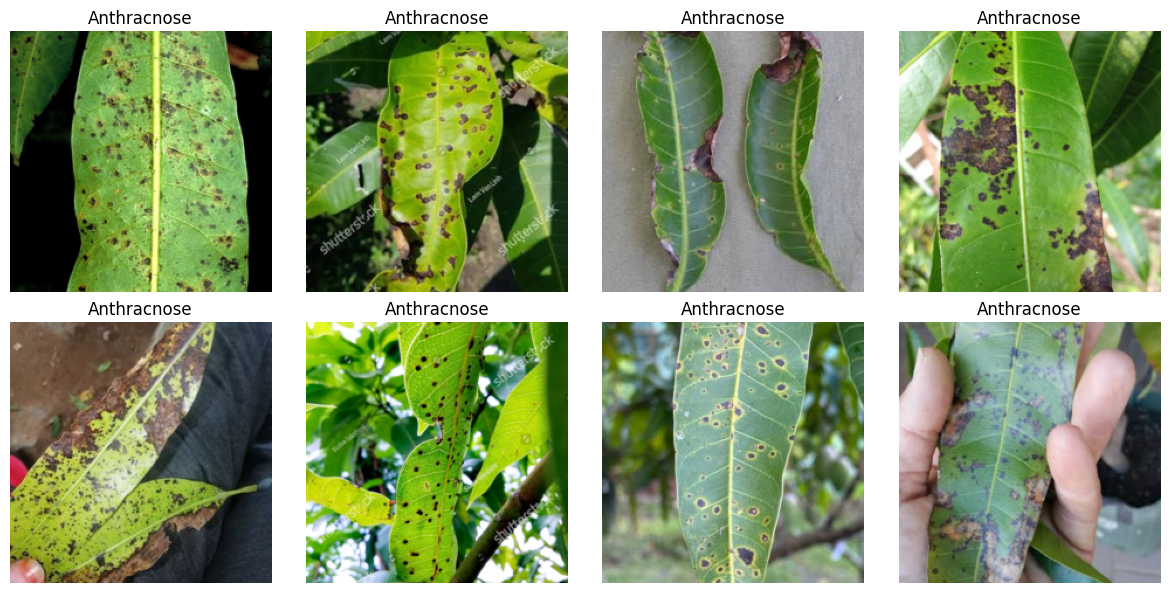

In [ ]:
# =====================================
# Dataset Summary
# =====================================

dataset_summary = pd.DataFrame({
    "Dataset": [
        "Train",
        "Validation",
        "Internal Test",
        "External Test"
    ],
    "Total Images": [
        len(train_dataset),
        len(val_dataset),
        len(test_dataset),
        len(external_dataset)
    ]
})

print(dataset_summary)

# =====================================
# Visualize External Images
# =====================================

import matplotlib.pyplot as plt
import numpy as np

images, labels = next(iter(external_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):

    if i >= len(images):
        break

    # Reverse normalization
    img = images[i].permute(1, 2, 0).numpy()

    img = img * np.array(std) + np.array(mean)
    img = np.clip(img, 0, 1)

    ax.imshow(img)

    ax.set_title(
        class_names[labels[i].item()]
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

14. CNN — Architecture

In [ ]:
import torch.nn as nn

class MangoCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1)
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = MangoCNN(num_classes=len(class_names)).to(device)
print('Device:', device)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
print(model)

Device: cpu
Trainable parameters: 391432
MangoCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNo

14.5 Helpers

In [ ]:
import time
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)

SEEDS = [0, 1, 2]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def evaluate(model, loader):
    """Return (metrics dict, y_true, y_pred). Share this function with the whole team."""
    model.eval()
    y_true, y_pred = [], []
    with torch.inference_mode():
        for x, y in loader:
            y_pred += model(x.to(device)).argmax(1).cpu().tolist()
            y_true += y.tolist()
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    metrics = {"accuracy": accuracy_score(y_true, y_pred),
               "precision": p, "recall": r, "f1": f1}
    return metrics, y_true, y_pred

15. CNN — Train    

**Loss**: CrossEntropyLoss (multi-class classification)     
**Optimizer**: Adam; learning rate = 0.001  
**Epochs**: 12  
**Selection**: Save the weights achieving the highest validation accuracy

In [ ]:
import os
import time
import torch
import torch.nn as nn

EPOCHS = 12
criterion = nn.CrossEntropyLoss()

def train_cnn(seed, save_dir="/content/drive/MyDrive/mango_models/cnn_runs"):
    set_seed(seed)
    model = MangoCNN(num_classes=len(class_names)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    # เพิ่มตัวเร่งความเร็ว Mixed Precision (ทำงานอัตโนมัติเมื่อใช้ GPU)
    use_amp = (device.type == "cuda")
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc = -1.0
    start_epoch = 1
    total_time = 0.0

    best_model_path = f"{save_dir}/mango_cnn_seed{seed}_best.pth"
    epoch_ckpt_path = f"{save_dir}/mango_cnn_seed{seed}_last_epoch.pth"

    if os.path.exists(epoch_ckpt_path):
        print(f"🔄 [seed {seed}] พบไฟล์ค้างไว้ กำลังโหลดเพื่อเทรนต่อ...")
        ckpt = torch.load(epoch_ckpt_path, map_location=device, weights_only=True)
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optimizer_state"])
        if "scaler_state" in ckpt and use_amp:
            scaler.load_state_dict(ckpt["scaler_state"])
        start_epoch = ckpt["epoch"] + 1
        best_val_acc = ckpt["best_val_acc"]
        history = ckpt["history"]
        total_time = ckpt["total_time"]

    for epoch in range(start_epoch, EPOCHS + 1):
        start = time.time()

        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            # non_blocking=True ช่วยส่งข้อมูลเข้า GPU เร็วขึ้นเมื่อใช้คู่กับ pin_memory=True
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True) # เร็วกว่า zero_grad() ปกติเล็กน้อย

            # คำนวณแบบ Mixed Precision (FP16)
            with torch.amp.autocast('cuda', enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss, train_acc = total_loss / total, correct / total

        model.eval()
        val_loss_sum, val_correct, val_total = 0.0, 0, 0
        with torch.inference_mode(), torch.amp.autocast('cuda', enabled=use_amp):
            for images, labels in val_loader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)
                outputs = model(images)
                val_loss_sum += criterion(outputs, labels).item() * labels.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += labels.size(0)
        val_loss, val_acc = val_loss_sum / val_total, val_correct / val_total

        for key, value in zip(history, (train_loss, val_loss, train_acc, val_acc)):
            history[key].append(value)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), best_model_path)

        total_time += (time.time() - start)

        torch.save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scaler_state": scaler.state_dict(),
            "best_val_acc": best_val_acc,
            "history": history,
            "total_time": total_time
        }, epoch_ckpt_path)

        print(f'[seed {seed}] Epoch {epoch:02d}/{EPOCHS} | '
              f'Train loss: {train_loss:.4f}, acc: {train_acc:.4f} | '
              f'Val loss: {val_loss:.4f}, acc: {val_acc:.4f} (Saved)')

    model.load_state_dict(torch.load(best_model_path, map_location=device, weights_only=True))
    if os.path.exists(epoch_ckpt_path):
        os.remove(epoch_ckpt_path)

    return model, history, best_val_acc, total_time


In [ ]:
import json
import os
from google.colab import drive

drive.mount('/content/drive')

RUN_DIR = "/content/drive/MyDrive/mango_models/cnn_runs"
os.makedirs(RUN_DIR, exist_ok=True)

results, runs = [], {}
for seed in SEEDS:
    res_path = f"{RUN_DIR}/seed{seed}_result.json"
    ckpt_path = f"{RUN_DIR}/seed{seed}.pth"

    if os.path.exists(res_path) and os.path.exists(ckpt_path):
        print(f"\n===== seed {seed}: already finished, loading from Drive =====")
        with open(res_path) as f:
            row = json.load(f)
        history = row.pop("history")
        model = MangoCNN(num_classes=len(class_names)).to(device)
        ck = torch.load(ckpt_path, map_location=device, weights_only=True)
        model.load_state_dict(ck["model_state"])
    else:
        print(f"\n===== seed {seed}: training =====")
        # 👇 จุดที่เพิ่มเข้ามา: ส่ง save_dir=RUN_DIR เข้าไป
        model, history, best_val, train_time = train_cnn(seed, save_dir=RUN_DIR)

        test_m, _, _ = evaluate(model, test_loader)
        ext_m, _, _ = evaluate(model, external_loader) # EXTERNAL
        row = {
            "seed": seed,
            "best_val_acc": float(best_val),
            "train_time_s": float(train_time),
            **{f"test_{k}": float(v) for k, v in test_m.items()},
            **{f"ext_{k}": float(v) for k, v in ext_m.items()}
        } # EXTERNAL

        torch.save({"model_state": model.state_dict(), "class_names": class_names}, ckpt_path)
        with open(res_path, "w") as f:
            json.dump({**row, "history": history}, f)
        print(f"saved seed {seed} -> {RUN_DIR}")

    model.eval()
    results.append(row)
    runs[seed] = (model, history)

results_df = pd.DataFrame(results)
display(results_df.round(4))
summary = results_df.drop(columns="seed").agg(["mean", "std"]).round(4)
display(summary)
results_df.to_csv("cnn_results.csv", index=False)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

===== seed 0: already finished, loading from Drive =====

===== seed 1: already finished, loading from Drive =====

===== seed 2: already finished, loading from Drive =====


,seed,best_val_acc,train_time_s,test_accuracy,test_precision,test_recall,test_f1,ext_accuracy,ext_precision,ext_recall,ext_f1
0,0,0.9500,8056.7321,0.9533,0.9550,0.9533,0.9529,0.2500,0.2521,0.2774,0.2334
1,1,0.9683,4913.0559,0.9617,0.9620,0.9617,0.9614,0.2438,0.3125,0.2438,0.2273
2,2,0.9700,4586.1729,0.9733,0.9734,0.9733,0.9733,0.2750,0.3603,0.2750,0.2585


,best_val_acc,train_time_s,test_accuracy,test_precision,test_recall,test_f1,ext_accuracy,ext_precision,ext_recall,ext_f1
mean,0.9628,5851.9869,0.9628,0.9635,0.9628,0.9625,0.2563,0.3083,0.2654,0.2397
std,0.0111,1916.3478,0.0100,0.0093,0.0100,0.0102,0.0165,0.0542,0.0188,0.0165


In [ ]:
best_seed = int(results_df.loc[results_df["best_val_acc"].idxmax(), "seed"])
model, history = runs[best_seed]
print("Model used for plots and demo: seed", best_seed)

Model used for plots and demo: seed 2


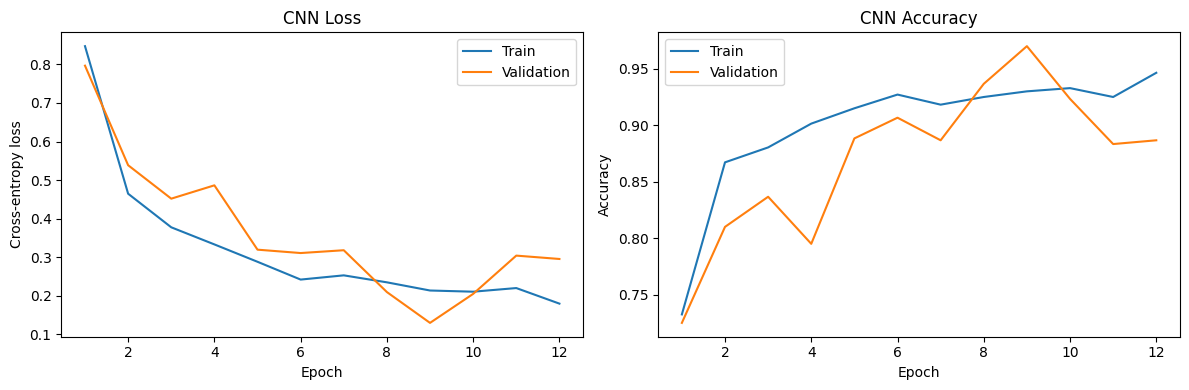

In [ ]:
epochs = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history['train_loss'], label='Train')
axes[0].plot(epochs, history['val_loss'], label='Validation')
axes[0].set(title='CNN Loss', xlabel='Epoch', ylabel='Cross-entropy loss')
axes[0].legend()
axes[1].plot(epochs, history['train_acc'], label='Train')
axes[1].plot(epochs, history['val_acc'], label='Validation')
axes[1].set(title='CNN Accuracy', xlabel='Epoch', ylabel='Accuracy')
axes[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
# model.eval()

# image, label = test_dataset[0]
# x = image.unsqueeze(0).to(device)

# feature_maps = []

# with torch.no_grad():
#     for i, layer in enumerate(model.features):
#         x = layer(x)

#         if i in [3, 7, 11, 15]:
#             feature_maps.append(x.cpu())

# fig, axes = plt.subplots(4, 8, figsize=(16, 8))

# for block, maps in enumerate(feature_maps):
#     for channel in range(8):
#         axes[block, channel].imshow(
#             maps[0, channel],
#             cmap="viridis"
#         )
#         axes[block, channel].set_title(
#             f"B{block+1} - CH{channel+1}"
#         )
#         axes[block, channel].axis("off")

# plt.tight_layout()
# plt.show()

16. CNN — Test


{'accuracy': 0.9733, 'precision': 0.9734, 'recall': 0.9733, 'f1': 0.9733}
                  precision    recall  f1-score   support

     Anthracnose       0.99      0.97      0.98        75
Bacterial Canker       0.99      0.97      0.98        75
  Cutting Weevil       1.00      1.00      1.00        75
        Die Back       0.99      1.00      0.99        75
      Gall Midge       0.95      0.99      0.97        75
         Healthy       0.99      0.99      0.99        75
  Powdery Mildew       0.95      0.93      0.94        75
     Sooty Mould       0.95      0.93      0.94        75

        accuracy                           0.97       600
       macro avg       0.97      0.97      0.97       600
    weighted avg       0.97      0.97      0.97       600



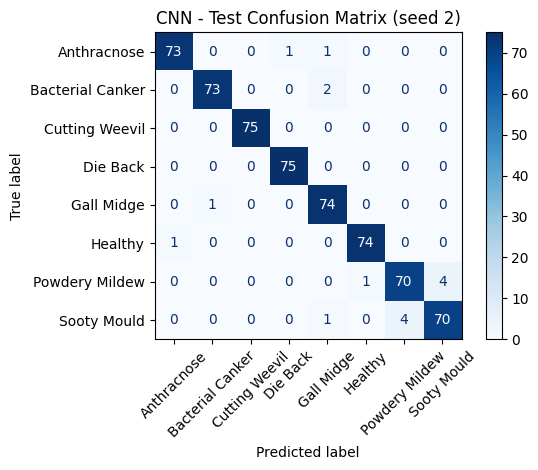

In [ ]:
# internal test
test_m, y_true, y_pred = evaluate(model, test_loader)
print({k: round(v, 4) for k, v in test_m.items()})
print(classification_report(
    y_true, y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=list(range(len(class_names))),
    display_labels=class_names, xticks_rotation=45, cmap='Blues'
)
plt.title(f'CNN - Test Confusion Matrix (seed {best_seed})')
plt.tight_layout()
plt.show()

{'accuracy': 0.275, 'precision': 0.3603, 'recall': 0.275, 'f1': 0.2585}
                  precision    recall  f1-score   support

     Anthracnose       0.16      0.40      0.23        20
Bacterial Canker       0.40      0.20      0.27        20
  Cutting Weevil       0.67      0.30      0.41        20
        Die Back       0.60      0.15      0.24        20
      Gall Midge       0.00      0.00      0.00        20
         Healthy       0.33      0.40      0.36        20
  Powdery Mildew       0.50      0.15      0.23        20
     Sooty Mould       0.22      0.60      0.32        20

        accuracy                           0.28       160
       macro avg       0.36      0.28      0.26       160
    weighted avg       0.36      0.28      0.26       160



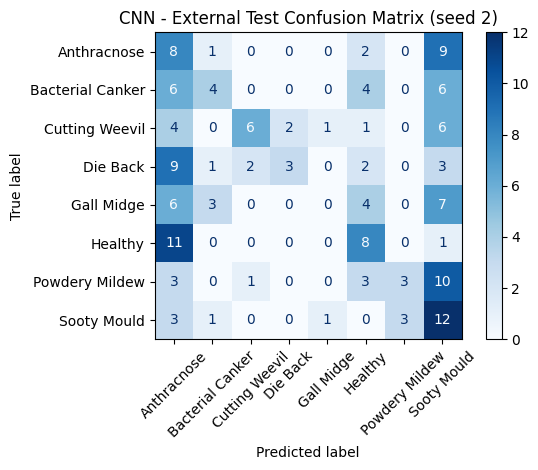

In [ ]:
# external test
test_m, y_true, y_pred = evaluate(model, external_loader)
print({k: round(v, 4) for k, v in test_m.items()})
print(classification_report(
    y_true, y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=list(range(len(class_names))),
    display_labels=class_names, xticks_rotation=45, cmap='Blues'
)
plt.title(f'CNN - External Test Confusion Matrix (seed {best_seed})')
plt.tight_layout()
plt.show()

17. Grad-CAM

In [ ]:
# Grad-CAM function + plotting helpers
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F


def grad_cam(model, x, target_layer):
    """x: tensor (1, 3, H, W) on `device`.
    Returns (cam in [0,1] with shape HxW, predicted class index, class probabilities)."""
    model.eval()
    store = {}

    def fwd_hook(module, inp, out):
        store["act"] = out.detach()                                   # feature maps A
        out.register_hook(lambda g: store.__setitem__("grad", g.detach()))  # dScore/dA

    handle = target_layer.register_forward_hook(fwd_hook)
    try:
        with torch.enable_grad():
            logits = model(x)
            pred = int(logits.argmax(1))
            model.zero_grad(set_to_none=True)
            logits[0, pred].backward()                                 # score of the predicted class
    finally:
        handle.remove()

    weights = store["grad"].mean(dim=(2, 3), keepdim=True)            # importance of each channel
    cam = F.relu((weights * store["act"]).sum(dim=1, keepdim=True))   # weighted sum, keep positives
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    probs = F.softmax(logits.detach(), dim=1)[0].cpu().numpy()
    return cam.cpu().numpy(), pred, probs


def denorm(x):
    m = torch.tensor(mean).view(3, 1, 1)
    s = torch.tensor(std).view(3, 1, 1)
    return (x.cpu() * s + m).clamp(0, 1).permute(1, 2, 0).numpy()


def show_gradcam(model, dataset, target_layer, indices, title, save_as=None):
    n = len(indices)
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6.6), squeeze=False)
    for j, k in enumerate(indices):
        x, y = dataset[k]
        cam, pred, probs = grad_cam(model, x.unsqueeze(0).to(device), target_layer)
        img = denorm(x)
        axes[0, j].imshow(img)
        axes[0, j].set_title(f"true: {class_names[y]}", fontsize=9)
        axes[1, j].imshow(img)
        axes[1, j].imshow(cam, cmap="jet", alpha=0.45)
        axes[1, j].set_title(f"pred: {class_names[pred]} ({probs[pred]:.0%})", fontsize=9,
                             color="green" if pred == y else "red")
        axes[0, j].axis("off")
        axes[1, j].axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=150)
    plt.show()


def first_index_per_class(df):
    """Row index of the first image of every class (dataset order == df order, shuffle=False)."""
    seen, picks = set(), []
    for k, lab in enumerate(df["label"]):
        if lab not in seen:
            seen.add(lab)
            picks.append(k)
    return picks

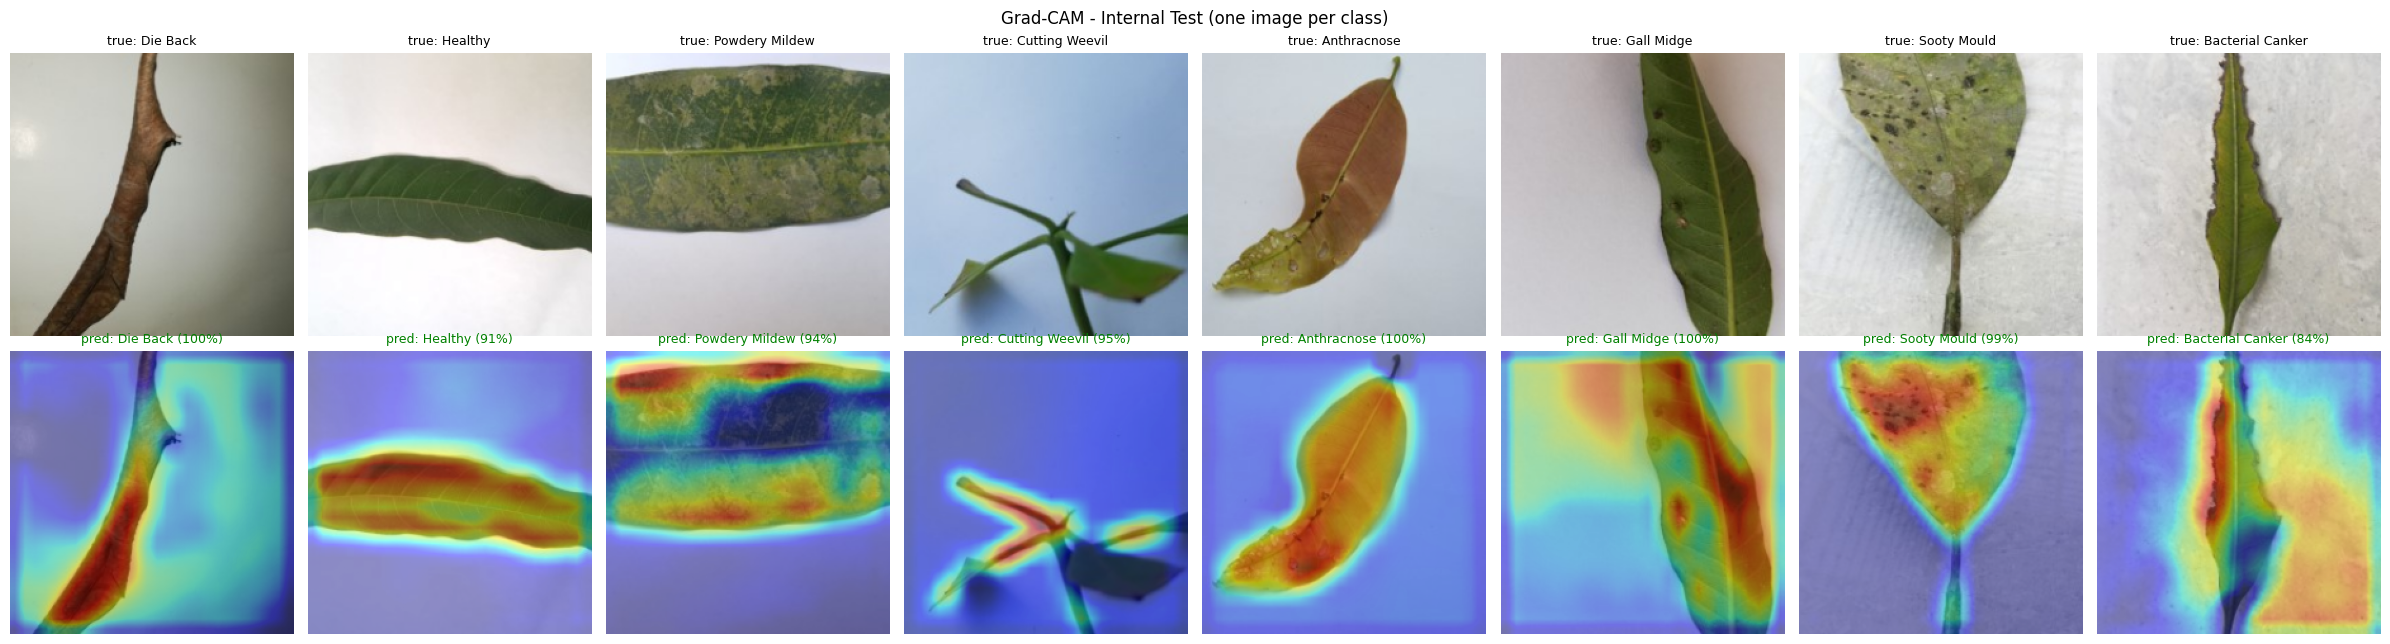

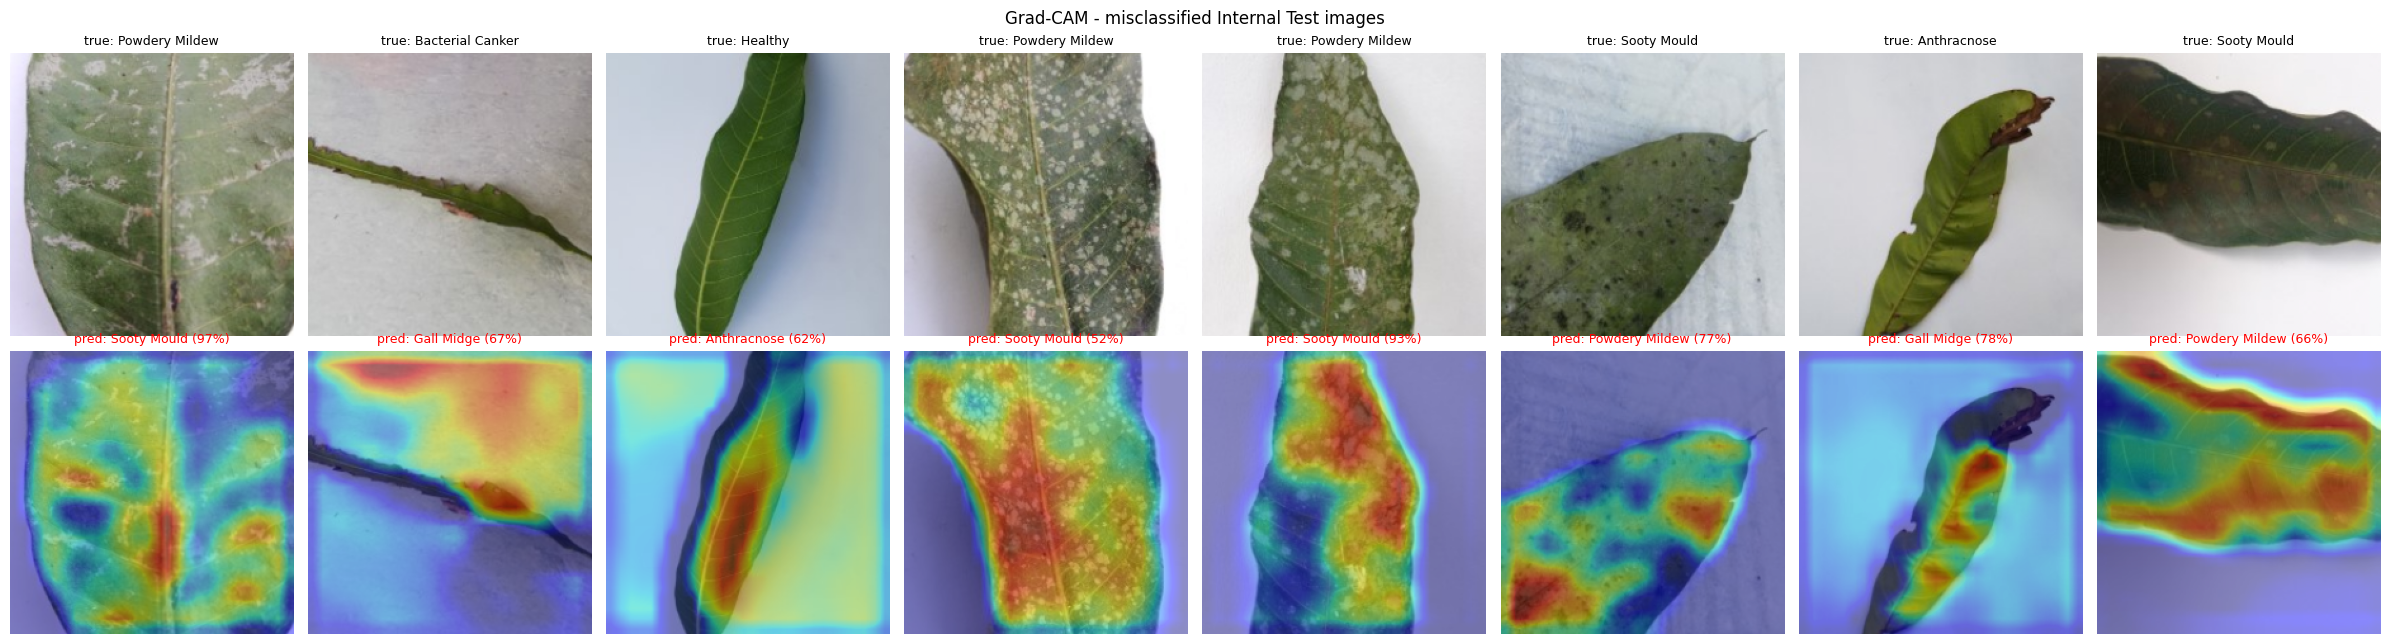

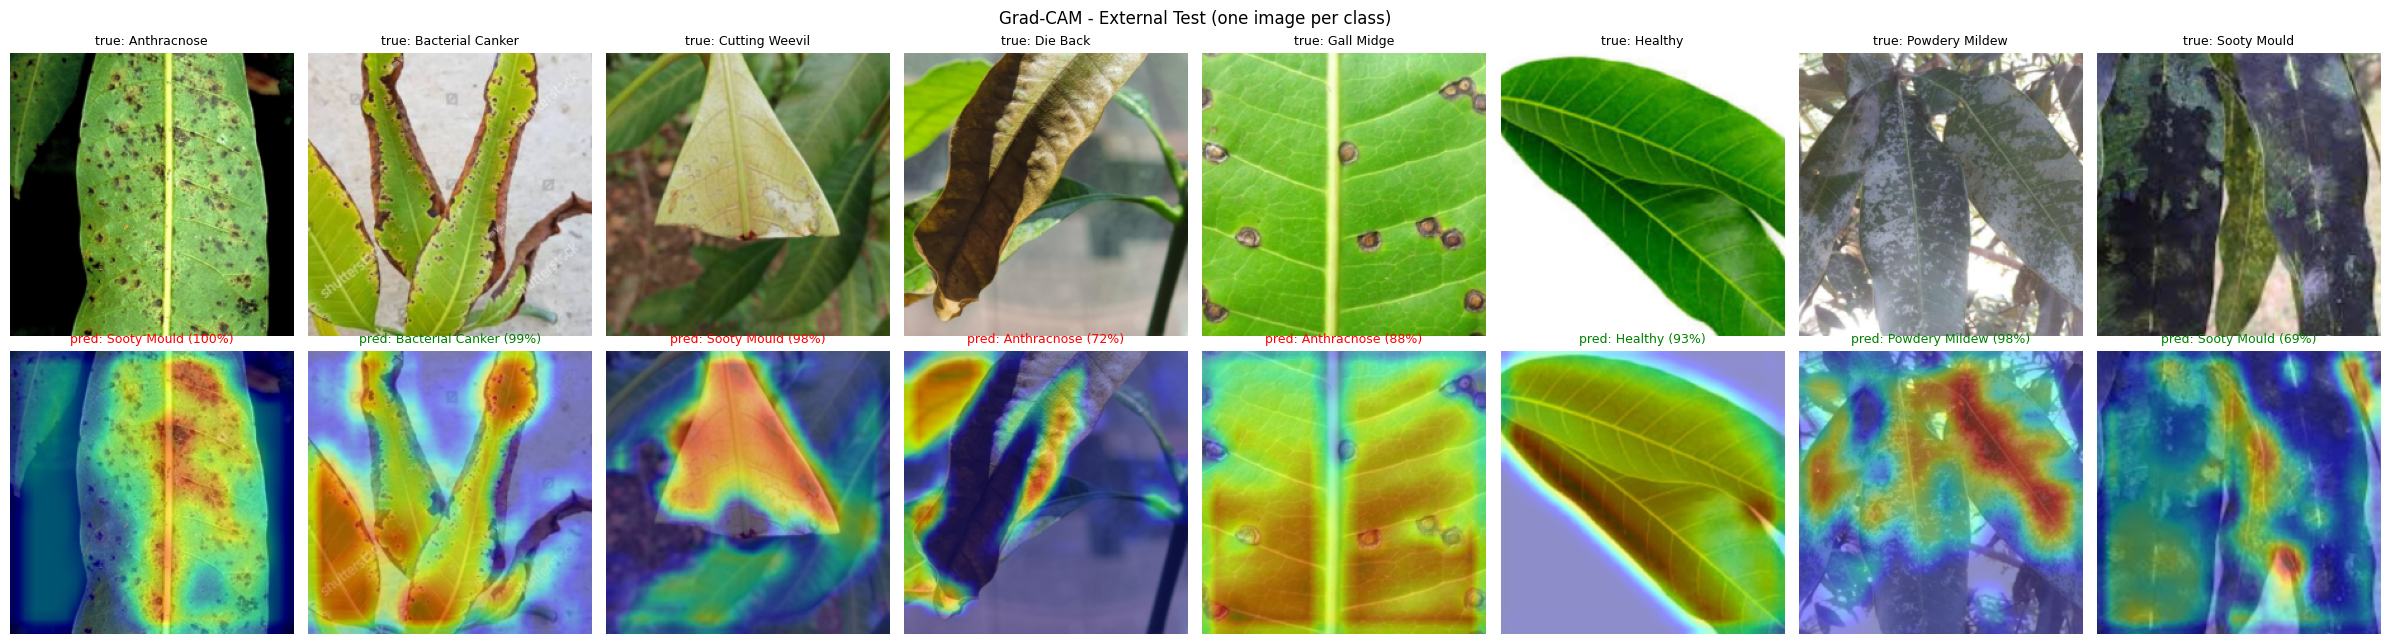

In [ ]:
# run it on the test set, the mistakes, and the external set

# Pick the target layer for the notebook you are in (keep ONE line):
target_layer = model.features[14]      # CNN notebook: last Conv-BN-ReLU block (28x28 map)
# target_layer = model.inception5b     # GoogLeNet notebook: last Inception block (7x7 map)

# 1) one Internal Test image per class
show_gradcam(model, test_dataset, target_layer, first_index_per_class(test_df),
             "Grad-CAM - Internal Test (one image per class)", save_as="gradcam_internal.png")

# 2) images the model got WRONG (most useful for the discussion slide)
_, y_true, y_pred = evaluate(model, test_loader)
wrong = [k for k, (t, p) in enumerate(zip(y_true, y_pred)) if t != p][:8]
if wrong:
    show_gradcam(model, test_dataset, target_layer, wrong,
                 "Grad-CAM - misclassified Internal Test images", save_as="gradcam_wrong.png")
else:
    print("No misclassified Internal Test images.")

# 3) External Test (your own photos)
show_gradcam(model, external_dataset, target_layer, first_index_per_class(external_df),
             "Grad-CAM - External Test (one image per class)", save_as="gradcam_external.png")

18. CNN — Demo (Upload a Mango Leaf Image)

Saving 29327fd1-9073-4970-9067-e61041e8500e.png to 29327fd1-9073-4970-9067-e61041e8500e (1).png
Image: 29327fd1-9073-4970-9067-e61041e8500e (1).png
Prediction: Sooty Mould
Confidence: 97.76%


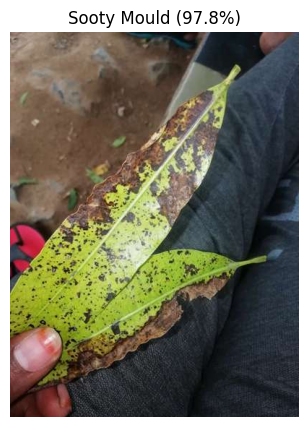

In [ ]:
from google.colab import files
from io import BytesIO

uploaded = files.upload()
if uploaded:
    filename, content = next(iter(uploaded.items()))
    image = Image.open(BytesIO(content)).convert('RGB')
    input_tensor = test_transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.inference_mode():
        probabilities = torch.softmax(model(input_tensor), dim=1)[0]

    predicted_idx = probabilities.argmax().item()
    predicted_class = class_names[predicted_idx]
    confidence = probabilities[predicted_idx].item()
    print(f'Image: {filename}')
    print(f'Prediction: {predicted_class}')
    print(f'Confidence: {confidence:.2%}')

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(f'{predicted_class} ({confidence:.1%})')
    plt.axis('off')
    plt.show()

19. Save the trained model

In [ ]:
from google.colab import drive
import os
drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/mango_models'      # all 3 people use the same shared folder
os.makedirs(SAVE_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
torch.save({
    "arch": "mango_cnn",
    "model_state": model.state_dict(),
    "class_names": class_names,
    "mean": list(mean), "std": list(std),
}, f"{SAVE_DIR}/cnn.pth")
print("saved", f"{SAVE_DIR}/cnn.pth")

saved /content/drive/MyDrive/mango_models/cnn.pth
